# Experiments 1-3 together: predictive utility, compression and cost

The central comparison holds each of six predictors fixed across decision and embedding recipes. Native-text references are shown separately as system comparisons. AUC and R-squared are fixed headline metrics; no best recipe or new model is selected here.

| Figure | Shows |
|---|---|
| Study map | the executable grid and the role of each experiment |
| Coverage | completed configurations across Experiments 1–3 |
| Decision versus embedding | every decision recipe against every embedding recipe within a predictor |
| Versus native systems | fixed-predictor recipes against each native-text system on matching folds |

## 1. Scope and provenance

In [1]:
import sys
from pathlib import Path
REPO_ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "pyproject.toml").is_file() and (p / "src").is_dir())
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))
import matplotlib.pyplot as plt
from src.utils.notebook_display import display_local, display_json, display_table
from src.utils.notebook_report import begin_report, report_section, record, finish_report
from src.utils.provenance import provenance
from src.visualize import figures, style
style.apply()
NOTEBOOK = '9. synthesis/01_representation_comparison'
begin_report()
save = figures.FigureSaver(NOTEBOOK)
report_section("1. Scope, provenance and saved evidence")
display_json("Notebook execution identity", provenance())
from src.evaluation.results import collect
from src.evaluation.notebook_study import planned_coverage, headline_summary, burden_table, contrast_summary
from src.visualize.study import coverage_figures, native_figures, burden_figures
from src.evaluation.endpoints import HEADLINES
status, folds, per_dataset, paired = collect()
summary = headline_summary(folds)
display_json("Saved result coverage", status)
display_json("Prespecified headline metrics", HEADLINES)
print("Only saved, validated folds are read. No fit, API call, download or hypothesis test runs here.")


Only saved, validated folds are read. No fit, API call, download or hypothesis test runs here.


## 2. The complete study grid and coverage

These are planned configurations, not independent statistical observations. Binary inner threshold fits are counted separately.

experiment,datasets,predictors,configurations,outer_fits,binary_inner_fits
experiment_1,18,6,3996,19980,9990
experiment_2,18,6,2268,11340,5670
experiment_3,18,3,54,270,135


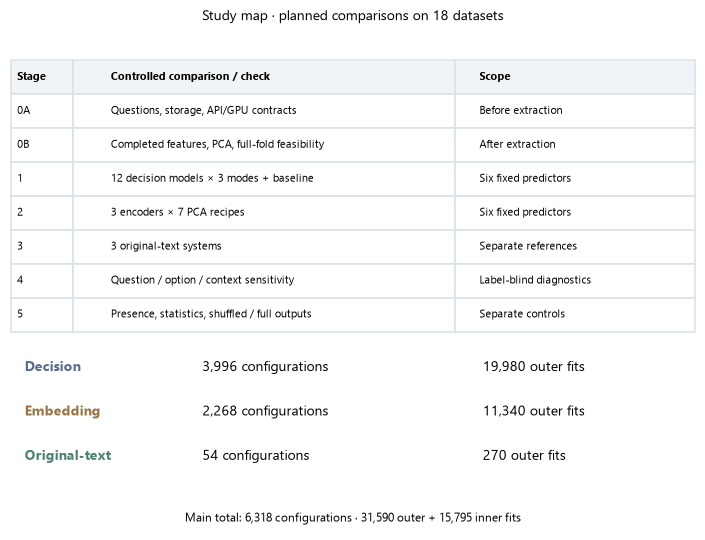

arm_id,phase,dataset_id,task_type,model_id,checkpoint_id,feature_set,provider,encoder,pca_scope,pca_components,split_id,metric,mean,descriptive_fold_sd,defined_folds


In [2]:
report_section('2. The complete study grid and coverage')
from src.evaluation.campaign import benchmark_plan
from src.evaluation.notebook_evidence import study_grid
from src.visualize.research import study_grid_figure
grid = study_grid(benchmark_plan())
display_table("Main grid, outer fits and binary inner fits", grid, preview_rows=3)
for fig, name, caption in [study_grid_figure(grid)]:
    save(fig, name, caption=caption)
    display_local(fig)
    plt.close(fig)
display_table("Complete primary headline results and exact recipe identities", summary[summary.phase.isin(["experiment_1", "experiment_2", "experiment_3"])])

## 3. Decision features versus every embedding recipe

Match dataset, predictor, checkpoint, split and fold. Each cell averages complete dataset effects, with coverage retained. J means total joint-PCA width; P32 means per-column PCA32.

In [3]:
report_section('3. Decision features versus every embedding recipe')
from src.evaluation.representation_views import decision_vs_embedding, measured_extraction
from src.visualize.representation_views import direct_comparison_figures
contrasts = decision_vs_embedding(folds)
display_table("Direct matched recipe effects and contributing dataset identities", contrast_summary(contrasts))
for fig, name, caption in direct_comparison_figures(contrasts):
    save(fig, name, caption=caption)
    display_local(fig)
    plt.close(fig)


## 4. Where do native-text systems sit?

This explicitly changes the prediction engine. Every fixed recipe is compared with every native reference on matching folds. No family is represented only by its test-selected winner.

In [4]:
report_section('4. Where do native-text systems sit?')
from src.evaluation.notebook_study import cross_system_contrasts
from src.visualize.study import cross_system_figures
system_contrasts = cross_system_contrasts(folds)
display_table("Descriptive cross-system differences and matched coverage", contrast_summary(system_contrasts))
for fig, name, caption in cross_system_figures(system_contrasts):
    save(fig, name, caption=caption)
    display_local(fig)
    plt.close(fig)


## 5. Observed extraction cost, fit time and representation width

Full extraction timings are distinct from pilots, retries and cache reuse. Hardware/run identities must accompany any cost-performance statement.

In [5]:
report_section('5. Observed extraction cost, fit time and representation width')
display_table("Measured full-extraction timing summaries", measured_extraction())
display_table("Saved predictive compute/width summaries", burden_table(folds, ["experiment_1", "experiment_2", "experiment_3"]))
record("Outcomes describe the selected 18 public tasks under shuffled row CV. Pretraining overlap can be unknown; repeated-text cohorts and absence of row-label inputs do not prove contamination-free pretrained weights. No raw target-unit errors or AUC/R-squared scores are pooled across task types.", "Scope of conclusions")

## Complete printed report

Everything displayed above is printed in section order. Individual predictions and the full metric store remain available in the referenced evaluation databases.

In [6]:
finish_report(NOTEBOOK, save.summary() + "\nNo fitting, inference or outcome-based method selection was performed.")

9. synthesis/01_representation_comparison

1. Scope, provenance and saved evidence


Notebook execution identity
{
  "code_sha256": "6093fc5317bd80b91eb6f5ad16ffcc4968d04678ac87785892673e679d730bf7",
  "git_head": "f359d40c4c0af52102f75e6d51529cdda3e340f7",
  "git_dirty": true,
  "tfm_library_pin": "4cf49431cab921fb727e883760ed535ca8e77f72 dm-library (remotes/origin/HEAD)\n 26156f36eb7676e8d9050547817346db548b0e85 tfm-library (remotes/origin/HEAD)\n 1c29213086a0ae76b8f95cdd8eccbb9db8d6ca87 vsc-library (remotes/origin/HEAD)",
  "environment": {
    "python": "3.12.10",
    "numpy": "2.5.3",
    "pandas": "2.3.3",
    "PyYAML": "6.0.3",
    "matplotlib": "3.11.2",
    "pyarrow": "25.0.1"
  }
}


Saved result coverage
{
  "status": "no_completed_folds"
}


Prespecified headline metrics
{
  "binary_classification": "roc_auc",
  "multiclass_classification": "roc_auc_ovr_macro",
  "regression": "r2"
}


2. The complete study grid and coverage


Main grid, outer fits and binary inner fits
  e